# House Price Prediction: a beginner-friendly machine learning walkthrough

This notebook predicts the price of a house from a few simple features (size, bedrooms, age, distance to the city center and whether it has a garden).

It is written for people who are **new to machine learning**. Every step explains *what* we do and *why* it matters, so you can follow along, run it, and change things to see what happens.

**What you will learn**
1. How to load and explore a dataset with `pandas`
2. How to spot patterns with simple charts
3. Why we split data into training and test sets
4. How to train two models: Linear Regression and Random Forest
5. How to evaluate a model with R², MAE and RMSE

## 1. Setup

We import the libraries we need:
- `numpy` and `pandas` to work with data
- `matplotlib` to draw charts
- `scikit-learn` for the machine learning models and metrics

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# A fixed "seed" makes random numbers repeatable,
# so you get exactly the same results every time you run the notebook.
SEED = 42

## 2. Create the dataset

To keep the project self-contained, we **generate a synthetic dataset**: fake but realistic houses built from a simple rule plus some random noise. This way you don't need to download anything, and because we know the rule, we can check whether the model learns it.

The rule behind the prices (in thousands of dollars) is roughly:
- every square meter adds value
- every extra bedroom adds a bit more
- older houses are a bit cheaper
- houses far from the center are cheaper
- a garden adds value

Then we add random noise, because real prices never follow a rule perfectly.

In [2]:
rng = np.random.default_rng(SEED)
n_houses = 500

size_m2 = rng.uniform(40, 220, n_houses).round(0)
bedrooms = np.clip((size_m2 / 40 + rng.normal(0, 0.7, n_houses)).round(), 1, 6).astype(int)
age_years = rng.integers(0, 60, n_houses)
distance_km = rng.uniform(0.5, 25, n_houses).round(1)
has_garden = rng.choice([0, 1], n_houses, p=[0.6, 0.4])

price = (
    90
    + 1.6 * size_m2
    + 8 * bedrooms
    - 0.9 * age_years
    - 4.5 * distance_km
    + 25 * has_garden
    + rng.normal(0, 25, n_houses)   # random noise
)

df = pd.DataFrame({
    "size_m2": size_m2,
    "bedrooms": bedrooms,
    "age_years": age_years,
    "distance_km": distance_km,
    "has_garden": has_garden,
    "price_k": price.round(1),
})

df.to_csv("houses.csv", index=False)   # saved so you can open it in Excel too
df.head()

,size_m2,bedrooms,age_years,distance_km,has_garden,price_k
0,179.0,5,31,14.6,0,301.1
1,119.0,3,20,20.3,0,195.4
2,195.0,5,33,4.7,1,416.4
3,166.0,4,10,24.5,0,265.9
4,57.0,1,5,12.7,0,111.3


## 3. Explore the data

Before training anything, we look at the data. This step catches problems early (missing values, strange numbers) and helps us understand what drives the price.

In [3]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
df.describe().round(1)

Rows and columns: (500, 6)
Missing values: 0


,size_m2,bedrooms,age_years,distance_km,has_garden,price_k
count,500.0,500.0,500.0,500.0,500.0,500.0
mean,129.2,3.2,28.8,13.1,0.4,247.3
std,51.6,1.4,17.2,7.1,0.5,106.6
min,41.0,1.0,0.0,0.6,0.0,14.9
25%,82.8,2.0,14.0,7.0,0.0,163.1
50%,130.0,3.0,27.0,12.7,0.0,243.8
75%,174.2,4.0,44.0,19.7,1.0,334.3
max,220.0,6.0,59.0,25.0,1.0,479.6


### Which features move together with the price?

**Correlation** goes from -1 to 1:
- close to **1**: when the feature goes up, the price goes up
- close to **-1**: when the feature goes up, the price goes down
- close to **0**: no clear straight-line relationship

In [4]:
df.corr()["price_k"].drop("price_k").sort_values(ascending=False).round(2)

size_m2        0.91
bedrooms       0.80
has_garden     0.08
age_years     -0.23
distance_km   -0.35
Name: price_k, dtype: float64

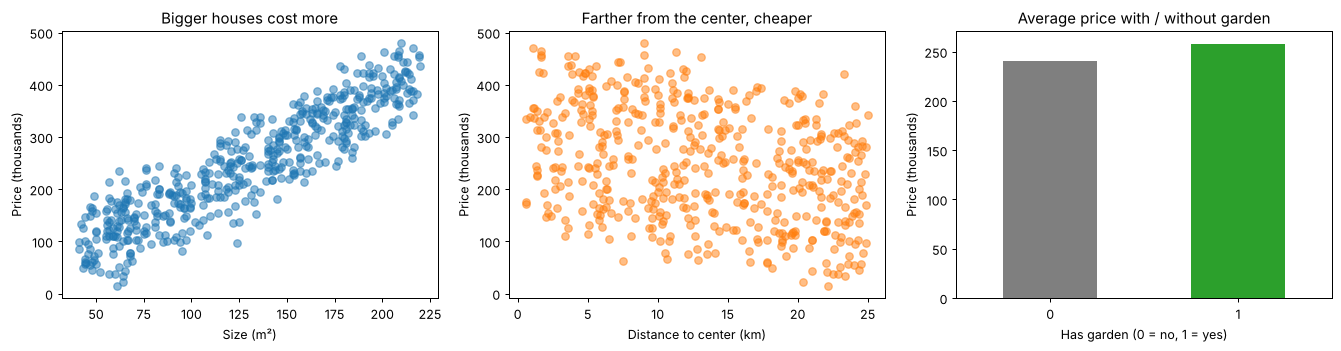

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(df["size_m2"], df["price_k"], alpha=0.5)
axes[0].set(title="Bigger houses cost more", xlabel="Size (m²)", ylabel="Price (thousands)")

axes[1].scatter(df["distance_km"], df["price_k"], alpha=0.5, color="tab:orange")
axes[1].set(title="Farther from the center, cheaper", xlabel="Distance to center (km)", ylabel="Price (thousands)")

df.groupby("has_garden")["price_k"].mean().plot.bar(ax=axes[2], color=["tab:gray", "tab:green"])
axes[2].set(title="Average price with / without garden", xlabel="Has garden (0 = no, 1 = yes)", ylabel="Price (thousands)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**What the charts tell us, in plain language**
- **Size** is the strongest driver: the points form a clear upward line.
- **Distance** pulls the price down: houses far from the center are cheaper on average.
- Houses **with a garden** cost more on average.
- **Bedrooms** also correlate with price, but partly because bigger houses have more bedrooms. The model will have to separate both effects.

## 4. Split into training and test sets

We hide part of the data from the model while it learns. Later we test the model on that hidden part.

**Why?** If we evaluated the model on the same houses it learned from, it could simply "memorize" them and look better than it really is. The test set simulates *new* houses the model has never seen.

We use 80% of the houses to train and 20% to test.

In [6]:
features = ["size_m2", "bedrooms", "age_years", "distance_km", "has_garden"]
X = df[features]       # inputs
y = df["price_k"]      # what we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print("Training houses:", len(X_train))
print("Test houses:    ", len(X_test))

Training houses: 400
Test houses:     100


## 5. Model 1: Linear Regression

Linear Regression finds the best straight-line rule of the form:

`price = intercept + (weight × size) + (weight × bedrooms) + ...`

It is simple, fast and **easy to interpret**: each weight tells us how much the price changes when that feature goes up by one unit.

In [7]:
linear = LinearRegression()
linear.fit(X_train, y_train)

weights = pd.DataFrame({"feature": features, "weight": linear.coef_.round(2)})
print("Intercept:", round(linear.intercept_, 2))
weights

Intercept: 91.11


,feature,weight
0,size_m2,1.59
1,bedrooms,8.26
2,age_years,-0.91
3,distance_km,-4.36
4,has_garden,19.87


Compare these weights with the rule we used to create the data (1.6 per m², 8 per bedroom, -0.9 per year, -4.5 per km, +25 for a garden). The model recovered them quite closely **without ever seeing the rule**, only the examples. That is the core idea of machine learning.

## 6. How good are the predictions?

We use three common metrics:

| Metric | What it means | Better when |
|---|---|---|
| **R²** | Share of the price variation the model explains (1.0 = perfect) | closer to 1 |
| **MAE** | Average error, in the same units as the price | lower |
| **RMSE** | Like MAE, but punishes big mistakes more | lower |

We always compute them on the **test set**.

In [8]:
def evaluate(model, name):
    """Return the three metrics of a model on the test set."""
    predictions = model.predict(X_test)
    return {
        "model": name,
        "R2": round(r2_score(y_test, predictions), 3),
        "MAE": round(mean_absolute_error(y_test, predictions), 1),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_test, predictions))), 1),
    }

evaluate(linear, "Linear Regression")

{'model': 'Linear Regression', 'R2': 0.952, 'MAE': 21.4, 'RMSE': 27.0}

## 7. Model 2: Random Forest

A Random Forest builds many decision trees and averages their answers. It can learn more complex, non-linear patterns, but it is harder to interpret than a straight line.

Let's see if it does better here.

In [9]:
forest = RandomForestRegressor(n_estimators=200, random_state=SEED)
forest.fit(X_train, y_train)

results = pd.DataFrame([evaluate(linear, "Linear Regression"),
                        evaluate(forest, "Random Forest")])
results

,model,R2,MAE,RMSE
0,Linear Regression,0.952,21.4,27.0
1,Random Forest,0.941,24.7,30.0


**Why does the simple model win?** Our data was created with a straight-line rule, so Linear Regression is a perfect match. Random Forest is more flexible, but here that flexibility doesn't help and it slightly overfits the noise.

Lesson: **a more complex model is not automatically better**. Always compare against a simple baseline.

### Predicted vs. actual prices

If the predictions were perfect, every point would sit on the dashed diagonal line.

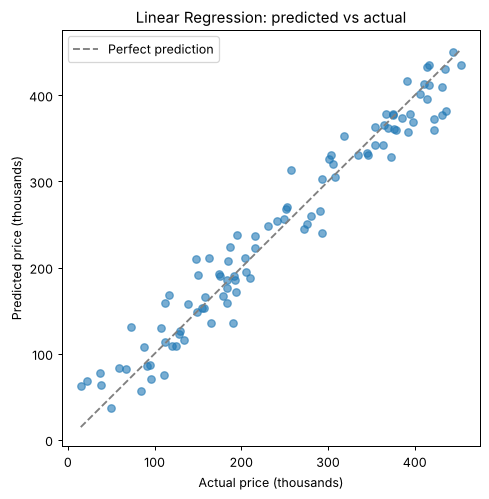

In [10]:
predictions = linear.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "--", color="gray", label="Perfect prediction")
plt.xlabel("Actual price (thousands)")
plt.ylabel("Predicted price (thousands)")
plt.title("Linear Regression: predicted vs actual")
plt.legend()
plt.show()

## 8. Try it yourself: predict a new house

Change the numbers below and run the cell to get a price estimate.

In [11]:
new_house = pd.DataFrame([{
    "size_m2": 120,
    "bedrooms": 3,
    "age_years": 10,
    "distance_km": 5,
    "has_garden": 1,
}])

estimate = linear.predict(new_house)[0]
print(f"Estimated price: ${estimate:,.1f} thousand")

Estimated price: $296.0 thousand


## 9. Ideas to experiment with

- Change `test_size` in step 4 (for example to `0.3`) and see how the metrics change.
- Increase the noise in step 2 (`rng.normal(0, 25, ...)` → `50`) and watch R² drop.
- Remove a feature from the `features` list and see which one hurts the model most.
- Change `n_estimators` in the Random Forest.

**Summary:** we created data, explored it, split it, trained two models and evaluated them on unseen houses. These same steps apply to almost any regression problem.